# ACTIVIDAD 1 #
En esta actividad crearemos un modelo que se encargara de clasificar los datos según el tipo de alojamiento (definido en room_type) a partir del resto de caracteristicas.

Este es un problemas supervisado, de clasificación multiclase y con aprendizaje offline.

Además, tendremos que hacerlo usando 3 algoritmos: Naive Bayes, K-Nearest-Kneighbors y arboles de decisión.

Primero, comenzaremos cargando los datos:

In [2]:
import pandas as pd
import numpy as np

input_file = "airbnb.csv"
df = pd.read_csv(input_file, header= 0)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13321 entries, 0 to 13320
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   neighbourhood_group             13321 non-null  str    
 1   neighbourhood                   13321 non-null  str    
 2   latitude                        13321 non-null  float64
 3   longitude                       13321 non-null  float64
 4   room_type                       13321 non-null  str    
 5   price                           13321 non-null  int64  
 6   minimum_nights                  13321 non-null  int64  
 7   number_of_reviews               13321 non-null  int64  
 8   reviews_per_month               13321 non-null  float64
 9   calculated_host_listings_count  13321 non-null  int64  
 10  availability_365                13321 non-null  int64  
dtypes: float64(3), int64(5), str(3)
memory usage: 1.1 MB


## Análisis exploratorio de los datos

El análisis exploratorio tiene como objetivo conocer los datos antes de construir cualquier modelo: qué forma tiene cada variable, si hay valores extremos o faltantes, y qué relación guarda cada una con el tipo de habitación (`room_type`), que es la variable objetivo.

El dataset contiene **13 321 anuncios** de Airbnb en Madrid (abril de 2017), con 11 variables. El análisis se organiza en los siguientes pasos:

1. **Información general.** Tipos de datos y número de registros de cada columna.
2. **Distribución de las variables numéricas.** Histogramas para ver su forma, sus valores extremos y su asimetría.
3. **Distribución de las variables categóricas.** Frecuencias de `room_type`, `neighbourhood_group` y `neighbourhood`, para detectar clases desbalanceadas y categorías con muy pocos registros.
4. **Análisis geográfico.** Mapas de puntos y de densidad, para ver cómo se reparten los anuncios y los precios por la ciudad.
5. **Relación con el objetivo.** Correlaciones y gráficos de dispersión entre variables, para identificar qué atributos separan mejor los tipos de habitación.

Las conclusiones de cada paso se incluyen en celdas de texto tras los gráficos. Las decisiones de limpieza y transformación que se derivan de este análisis se aplican después, en la sección de preparación de los datos.


In [3]:
import pandas as pd
import numpy as np

input_file = "airbnb.csv"
df = pd.read_csv(input_file, header= 0)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13321 entries, 0 to 13320
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   neighbourhood_group             13321 non-null  str    
 1   neighbourhood                   13321 non-null  str    
 2   latitude                        13321 non-null  float64
 3   longitude                       13321 non-null  float64
 4   room_type                       13321 non-null  str    
 5   price                           13321 non-null  int64  
 6   minimum_nights                  13321 non-null  int64  
 7   number_of_reviews               13321 non-null  int64  
 8   reviews_per_month               13321 non-null  float64
 9   calculated_host_listings_count  13321 non-null  int64  
 10  availability_365                13321 non-null  int64  
dtypes: float64(3), int64(5), str(3)
memory usage: 1.1 MB


In [4]:
df["room_type"].value_counts()

room_type
Entire home/apt    7926
Private room       5203
Shared room         192
Name: count, dtype: int64

En este breve analisis, podemos observar varias cosas: 
- No existe ningun valor nulo
- No todos los atributos/features son númericos. "neighbourhood_group" y "neighbourhood" son string, por lo tanto, deberemos de codificar dichas variables (ya sea mediante One-Hot Encoding o Ordinal Encoding)
- La variable que buscamos poder predecir tiene tres posibles valores y que dichos valores aparecen con una distribución desigual. Sera imporante esto ya que, si queremos que los modelos funcionen adecuadamente, tendremos que estratificar los datos al realizar la separación entre los conjuntos de entrenamiento y test

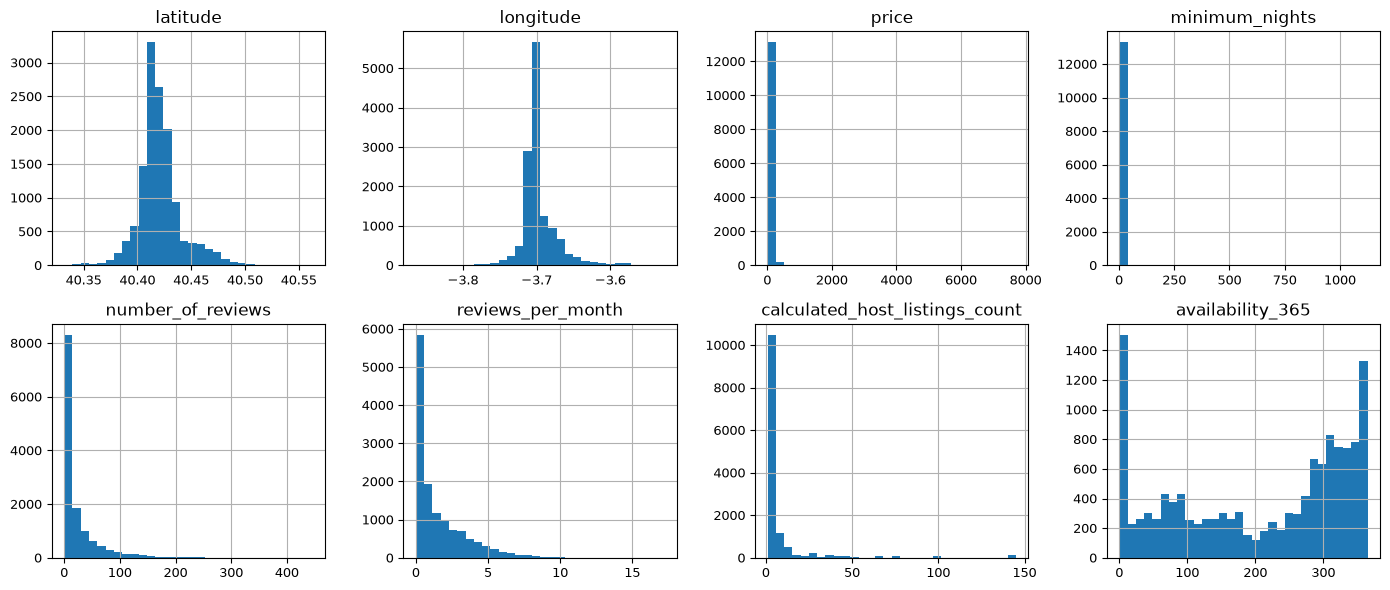

In [5]:
import matplotlib.pyplot as plt

df.hist(layout=(2, 4), figsize=(14, 6), bins=30,  xlabelsize=9, ylabelsize=9)   # 2x4 = 8 espacios
plt.tight_layout()
plt.show()

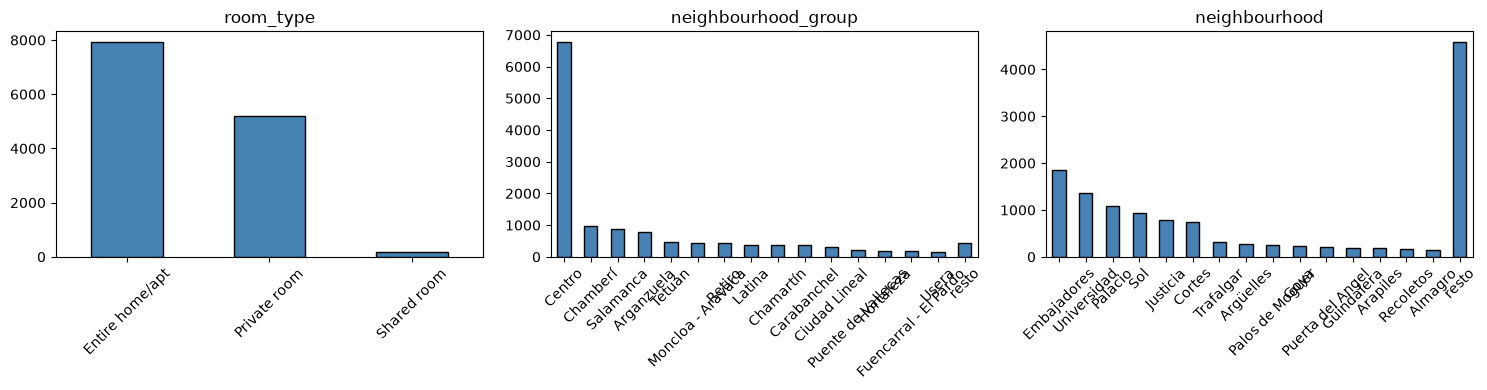

In [6]:
def top_con_resto(serie, top_n=15):
    counts = serie.value_counts()
    top = counts.head(top_n)
    resto = counts.iloc[top_n:].sum()
    if resto > 0:
        top = pd.concat([top, pd.Series({"resto": resto})])
    return top

categorical_cols = ["room_type", "neighbourhood_group", "neighbourhood"]
n = len(categorical_cols)
fig, axes = plt.subplots(1, n, figsize=(5*n, 4))
for ax, col in zip(axes, categorical_cols):
    top_con_resto(df[col]).plot(kind="bar", ax=ax, color="steelblue", edgecolor="black")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Como podemos observar en los histogramas, los valores numéricos estan muy sesgados (asimétricos) y tienen valores extremos. Esto, nos condicionara a la hora de prepararlos antes de suministrarselos al modelo.

Para las variables categóricas he optado por crear una gráfica de barras para mostrar las veces que aparecen cada uno de los tipos. Lo he diseñado de tal manera que muestre hasta un máximo de 15 tipos distintos ordenados de mayor número de apariciones a menor y, si hay más, las variables restantes aparezca de forma conjunta en "resto". De estos gráficos de barras podemos extraer:
- En "room_type", "shared_rooms" aparece mucho menos que los otros dos tipos
- En "neighbourhood_group", "centre" aparece mucho más que el resto
- En "neighbourhood", los datos aparecen de forma mucho más repartida


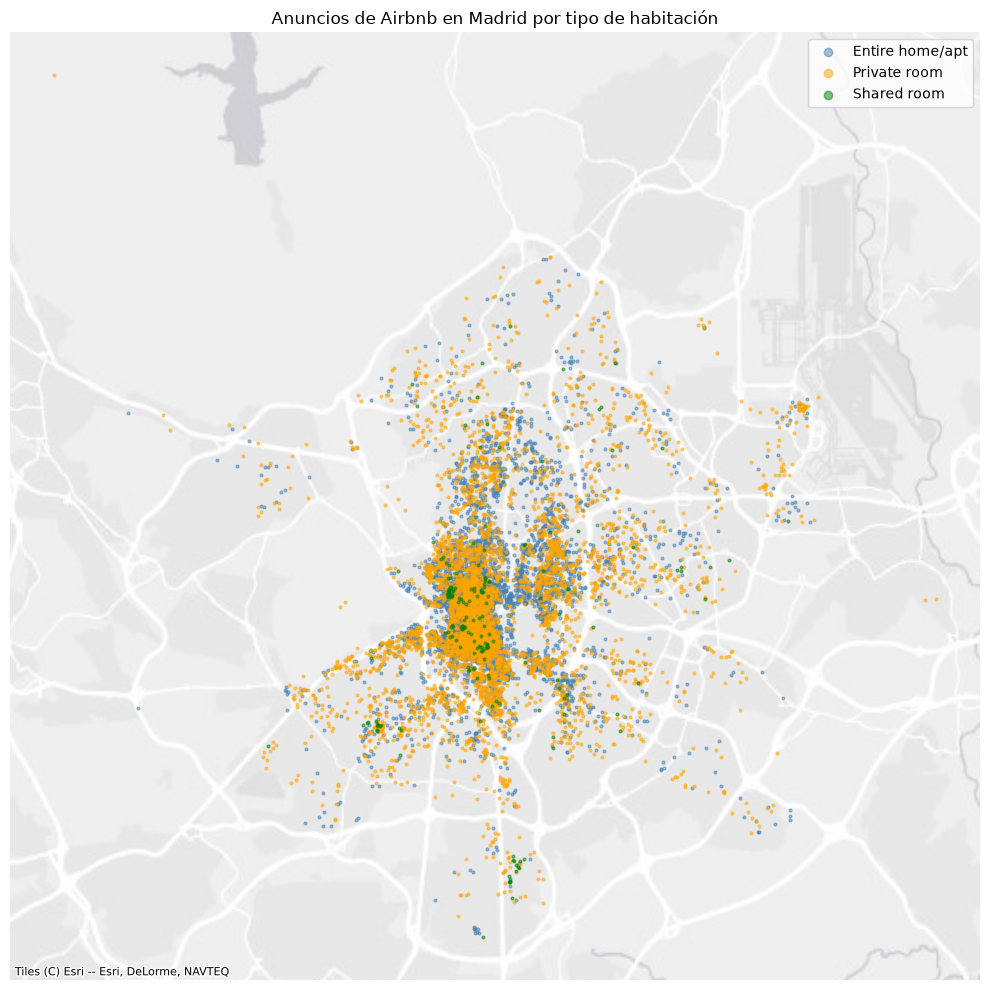

In [7]:
import contextily as ctx
import matplotlib.pyplot as plt
import numpy as np

# Convierte latitud/longitud a la proyección de los mapas web (Web Mercator),
# para que el mapa no se vea deformado
R = 6378137
df["x"] = np.radians(df["longitude"]) * R
df["y"] = np.log(np.tan(np.pi / 4 + np.radians(df["latitude"]) / 2)) * R

colores = {"Entire home/apt": "steelblue", "Private room": "orange", "Shared room": "green"}

fig, ax = plt.subplots(figsize=(10, 10))
for tipo, color in colores.items():
    sub = df[df["room_type"] == tipo]
    ax.scatter(sub["x"], sub["y"], s=4, alpha=0.5, color=color, label=tipo)

ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas)   # fondo claro y discreto
ax.set_axis_off()
ax.legend(loc="upper right", markerscale=3)
ax.set_title("Anuncios de Airbnb en Madrid por tipo de habitación")
plt.tight_layout()
plt.savefig("mapa_room_type.png", dpi=200, bbox_inches="tight")   # para insertarlo en el informe
plt.show()


En el mapa podemos observar como las zonas centrales contienen más vivienda miestras que en las más lejanas la vivienda esta más esparcida. Sin embargo, no se puede establecer una correlación clara entre la posición en el mapa y el "type_room".

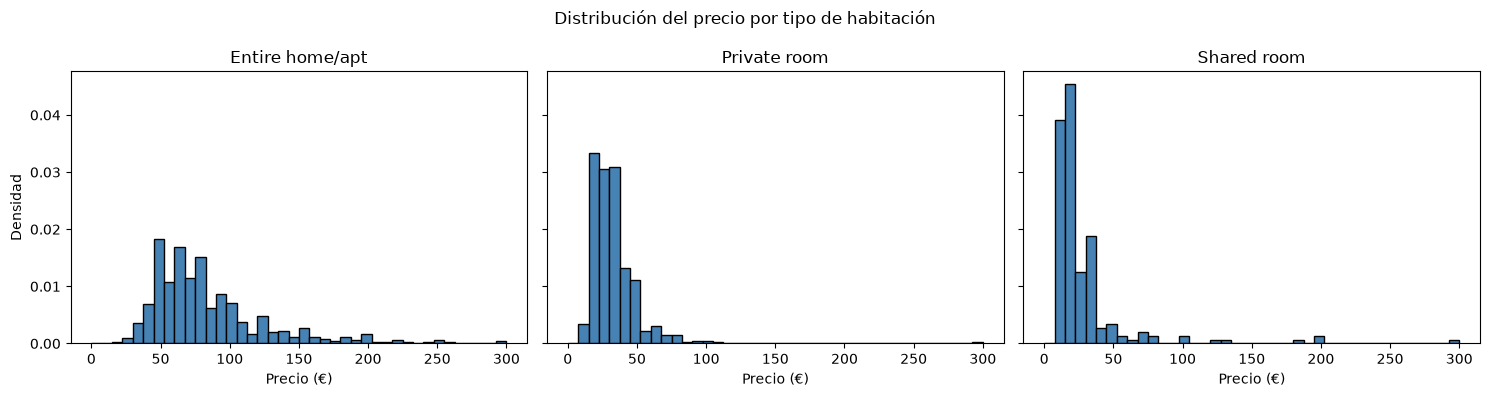

In [8]:
import matplotlib.pyplot as plt

tipos = df["room_type"].unique()
fig, axes = plt.subplots(1, len(tipos), figsize=(5 * len(tipos), 4), sharex=True, sharey=True)

for ax, tipo in zip(axes, tipos):
    ax.hist(
        df.loc[df["room_type"] == tipo, "price"],
        bins=40,
        range=(0, 300),
        density=True,
        color="steelblue",
        edgecolor="black",
    )
    ax.set_title(tipo)
    ax.set_xlabel("Precio (€)")

axes[0].set_ylabel("Densidad")
fig.suptitle("Distribución del precio por tipo de habitación")
plt.tight_layout()
plt.show()


En este histograma representamos el precio por el tipo de habitación. "Shared room" son las más baratas y "Entire home/apt" las más caras.

In [30]:
dummies = pd.get_dummies(df["room_type"], prefix="room").astype(int)
numericas = df.select_dtypes("number")

corr_room = pd.concat([numericas, dummies], axis=1).corr()
corr_room.loc[dummies.columns, numericas.columns].round(3)


,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,x,y
room_Entire home/apt,-0.007,-0.069,0.232,0.030,0.140,0.142,0.097,-0.013,-0.069,-0.007
room_Private room,0.016,0.070,-0.222,-0.026,-0.131,-0.132,-0.097,0.006,0.070,0.016
room_Shared room,-0.038,-0.003,-0.046,-0.015,-0.040,-0.043,-0.003,0.030,-0.003,-0.038


En esta tabla de correlación de Pearson comprobamos que las principales correlaciones de la variable room_type es con price, number_of_review y reviews_per_month

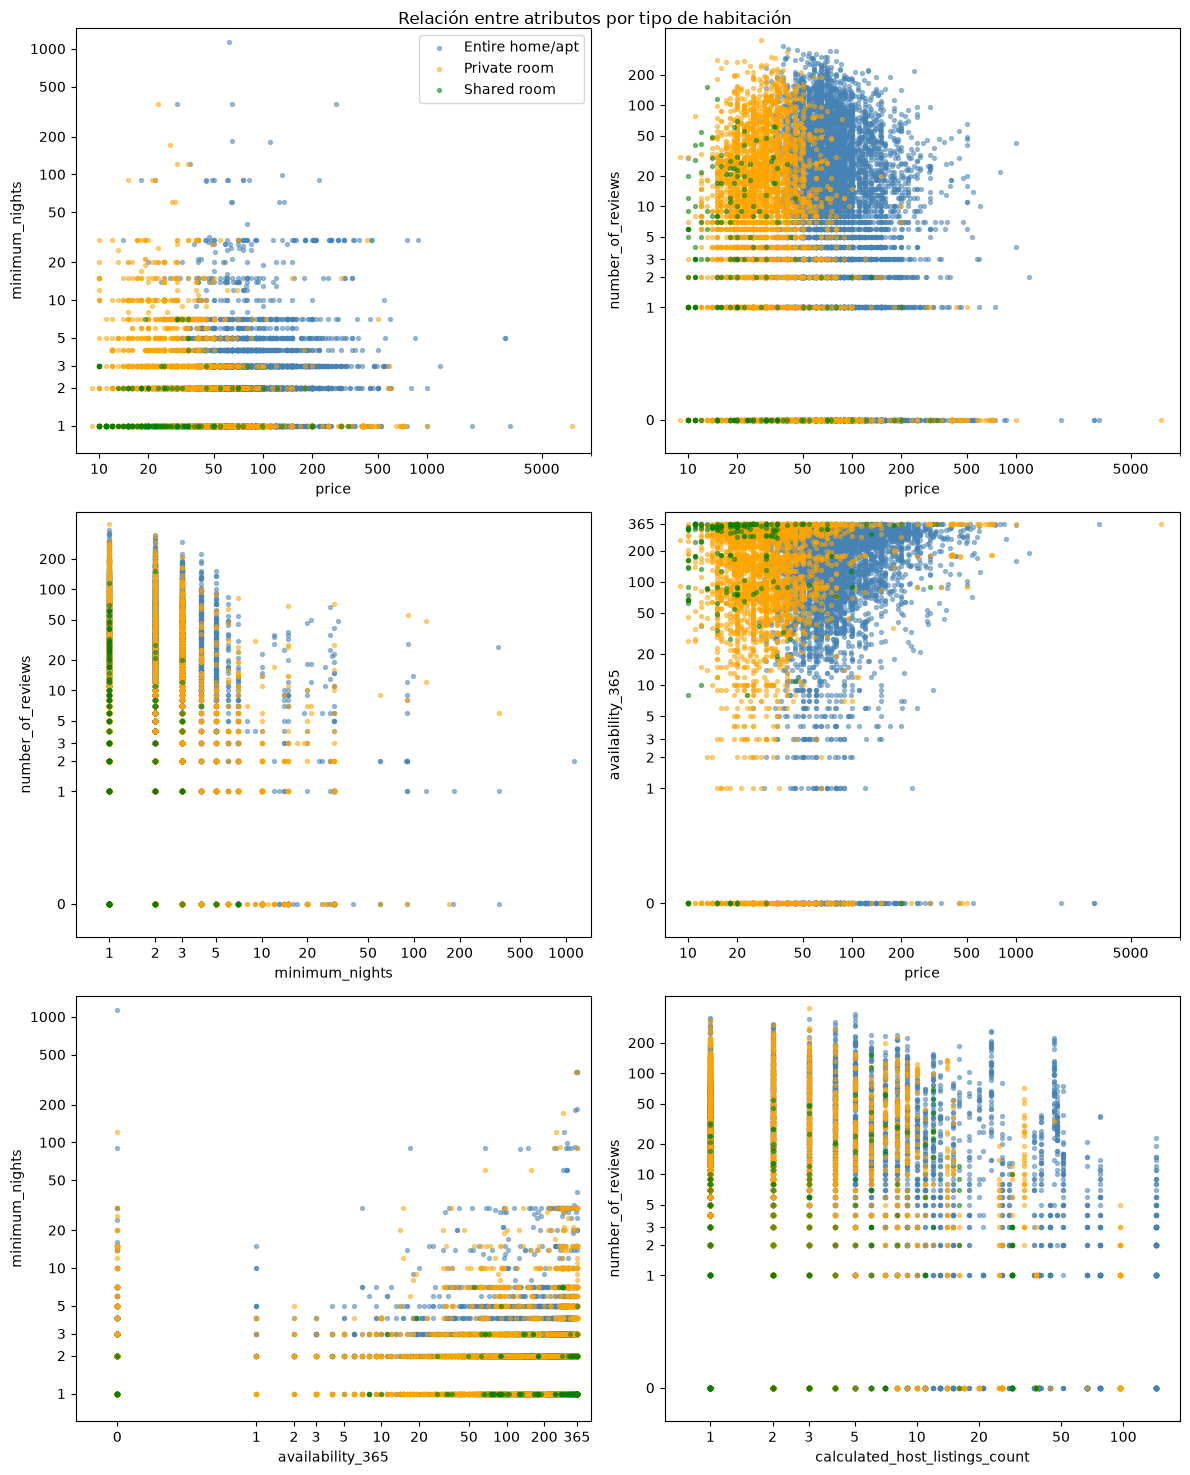

In [10]:
from matplotlib.ticker import NullFormatter

pares = [
    ("price", "minimum_nights"),
    ("price", "number_of_reviews"),
    ("minimum_nights", "number_of_reviews"),
    ("price", "availability_365"),
    ("availability_365", "minimum_nights"),
    ("calculated_host_listings_count", "number_of_reviews"),
]

marcas = [0, 1, 2, 3, 5, 10, 20, 50, 100, 200, 500, 1000, 5000]

def eje_legible(ax, eje, datos):
    minimo, maximo = datos.min(), datos.max()

    ticks = [m for m in marcas if minimo <= m <= maximo]
    if maximo == 365:          # availability_365: marca el máximo en lugar de 500
        ticks.append(365)
    etiquetas = [str(m) for m in ticks]

    # Límites ajustados a los datos, para que no quede espacio vacío por debajo de 0
    inferior = -0.3 if minimo == 0 else minimo * 0.8
    superior = maximo * 1.3

    if eje == "x":
        ax.set_xscale("symlog", linthresh=1)
        ax.set_xticks(ticks, labels=etiquetas)
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_xlim(inferior, superior)
    else:
        ax.set_yscale("symlog", linthresh=1)
        ax.set_yticks(ticks, labels=etiquetas)
        ax.yaxis.set_minor_formatter(NullFormatter())
        ax.set_ylim(inferior, superior)


fig, axes = plt.subplots(3, 2, figsize=(12, 15))

for ax, (x, y) in zip(axes.flat, pares):
    for tipo, color in colores.items():
        sub = df[df["room_type"] == tipo]
        ax.scatter(sub[x], sub[y], s=8, alpha=0.5, color=color, label=tipo)

    eje_legible(ax, "x", df[x])
    eje_legible(ax, "y", df[y])
    ax.set_xlabel(x)
    ax.set_ylabel(y)

axes[0, 0].legend()
fig.suptitle("Relación entre atributos por tipo de habitación")
plt.tight_layout()
plt.show()


En estas gráficas vemos enfrentamos varia variables (minimum_nights-price, number_of_reviews-price, number_of_reviews-minimum_nights y availability_365-price) para comprobar como estas combinaciones pueden llegar a influir en la variable objetivo (type_room). Para mejorar la legibilidad, las hemos representado en escala logarítmica.

De estas gráficas podemos extraer que el principal diferenciador entre tipos de habitación es la variable "price". Las habitaciones privadas y compartidas se concentran en los precios más bajos, mientras que las viviendas completas ocupan los precios más altos.
La pareja minimum_nights-price muestra que, además del precio, el número mínimo de noches también aporta información: Las viviendas completos suelen exigir más noches.
En number_of_reviews–minimum_nights no se aprecia una relación lineal. Los anuncios con más reseñas son los que piden 2 o 3 noches; tanto los de 1 noche como los que exigen estancias largas tienen menos reseñas. Destaca que las habitaciones compartidas suelen exigir menos noches que el resto de tipos.
En availability_365–price observamos que la disponibilidad no ayuda a diferenciar entre viviendas completas y habitaciones privadas, pero las habitaciones compartidas tienen, de media, más disponibilidad que las otras dos.
En minimum_nights–availability_365 no se aprecia correlación entre ambas variables. Aun así, las habitaciones compartidas aparecen sobrerrepresentadas en la zona del gráfico con más disponibilidad y menos noches mínimas.
Por último, en number_of_reviews–calculated_host_listings_count (número de anuncios publicados por el mismo anfitrión) observamos que cuantos más anuncios tiene un anfitrión, más probable es que se trate de una vivienda completa: pasa del 57 % entre anfitriones con un solo anuncio al 74 % entre los que tienen más de 10. El número de reseñas, en cambio, no muestra relación con esta variable.

Se descartó crear variables combinadas: las pruebas realizadas no mejoraron la correlación con room_type respecto a las variables originales, y mantenerlas simples facilita interpretar los resultados.

## Preparación de los datos

En esta sección preparamos los datos para los modelos de clasificación. Siguiendo el enunciado, el objetivo es **predecir `room_type`** a partir del resto de variables. Las transformaciones se agruparán en un pipeline, de forma que se ajusten solo con los datos de entrenamiento y se apliquen igual al conjunto de test.



In [11]:
print(
    f"Valores únicos en neighbourhood: {df['neighbourhood'].nunique()} | "
    f"Valores únicos en neighbourhood_group: {df['neighbourhood_group'].nunique()}"
)

Valores únicos en neighbourhood: 126 | Valores únicos en neighbourhood_group: 21


In [12]:
df['neighbourhood'].value_counts(ascending=True).head(10)

neighbourhood
El Pardo          1
Orcasitas         2
Cuatro Vientos    3
Rosas             4
Hellín            4
Santa Eugenia     4
El Plantío        4
Pavones           4
El Goloso         4
Fuentelareina     5
Name: count, dtype: int64

Tras esto, tendriamos que comprobar cuantos valores vacios hay y tratarlos (ya sea usando un imputer para asignarle un valor o eliminando dichas instancias directamente). Como ya hemos comprobado que no existe ningun valor nulo este paso nos lo podemos saltar. Por lo tanto, lo siguiente que haremos sera tratar los valores categóricos para que puedan ser usados por los modelos predictivos.
Los valores categóricos pueden ser tratados de dos formas:
1- Usando OrdinalEncoder, el cual es util cuando las variables tienen algun tipo de relación de orden entre ellas (lo cual no es el caso)
2- Usando OneHotEncoder, crea una nueva columna por cada una de los valores que puede contener. neighbourhood tiene 126 valores distintos y neighbourhood_group sólo 21. Usar las dos seria redundante, ya que se supone que contienen la misma información, por lo tanto, para realizar las predicciones, solo usaremos neighbourhood_group ya que en neighbourhood hay demasiadas variables y muchas de ellas aparecen muy pocas veces.


Antes de cualquier transformación, separamos los datos en entrenamiento (80 %) y test (20 %), manteniendo la proporción de cada tipo de habitación con `stratify`.

In [13]:
from sklearn.model_selection import train_test_split

numericas = [
    "latitude", "longitude", "price", "minimum_nights", "number_of_reviews",
    "reviews_per_month", "calculated_host_listings_count", "availability_365",
]
categoricas = ["neighbourhood_group"]

X = df[numericas + categoricas]
y = df["room_type"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

(10656, 9) (2665, 9)


In [14]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
scaler = StandardScaler()

con_cola = [
    "price", "minimum_nights", "number_of_reviews",
    "reviews_per_month", "calculated_host_listings_count",
]
sin_cola = ["latitude", "longitude", "availability_365"]

log_y_escala = make_pipeline(FunctionTransformer(np.log1p), StandardScaler())

preprocessing = ColumnTransformer([
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas),
    ("con_cola", log_y_escala, con_cola),
    ("sin_cola", StandardScaler(), sin_cola),
], sparse_threshold=0)

Como se observa en los histogramas, algunas variables están muy concentradas en valores bajos y tienen una cola larga de valores altos y muy dispersos (`price`, `minimum_nights`, `number_of_reviews`, `reviews_per_month` y `calculated_host_listings_count`). Estos valores extremos distorsionan la media y la desviación típica, de forma que `StandardScaler` aplicado directamente comprimiría la mayoría de los anuncios en un rango muy estrecho. Para evitarlo, aplicamos primero un logaritmo (`np.log1p`) a estas variables y después el `StandardScaler`. Las variables `latitude`, `longitude` y `availability_365` no presentan una cola tan marcada, así que solo se escalan.


## Creación y entrenamiento de los modelos

En esta sección entrenamos y comparamos los tres métodos de clasificación estudiados en el tema 3: **Naive Bayes**, **K vecinos más próximos (KNN)** y **árboles de decisión**. El objetivo es predecir `room_type` a partir de las variables seleccionadas, usando el preprocesado descrito en la sección anterior.

Cada modelo se construye dentro de un **pipeline** que incluye el mismo preprocesado, de forma que el ajuste de los escaladores y codificadores se hace solo con los datos de entrenamiento en cada partición de validación. Así la comparación entre modelos es justa y no hay fugas de información desde el conjunto de prueba.

El proceso se organiza en los siguientes pasos:

1. **Modelos base.** Entrenamos los tres métodos con sus parámetros por defecto y los evaluamos con validación cruzada de 10 particiones, usando la exactitud (accuracy) como métrica.
2. **Afinación de hiperparámetros.** Para KNN buscamos el valor óptimo de K, y para los árboles de decisión exploramos `max_leaf_nodes`, `min_samples_split` y `max_depth`, con `GridSearchCV`. Naive Bayes no tiene hiperparámetros que afinar.
3. **Evaluación final.** Comparamos los modelos sobre el conjunto de prueba, que no se ha usado para elegir ningún parámetro.

Como las clases no están balanceadas, en cada modelo se valorará el uso del parámetro de balanceo cuando exista, y se revisará además el balanced accuracy, para no interpretar un accuracy alto como un buen resultado si el modelo solo acierta con las clases mayoritarias.


In [15]:
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

n_clases = y_train.nunique()

modelos = {
    "Naive Bayes": GaussianNB(priors=np.full(n_clases, 1 / n_clases)),
    "KNN": KNeighborsClassifier(),
    "Árbol de decisión": DecisionTreeClassifier(class_weight='balanced', random_state=42),
}

for nombre, clasificador in modelos.items():
    pipe = make_pipeline(preprocessing, clasificador)
    scores = cross_val_score(pipe, X_train, y_train, cv=10, scoring="accuracy")
    print(f"{nombre}: accuracy medio = {scores.mean():.4f} (± {scores.std():.4f})")

Naive Bayes: accuracy medio = 0.0739 (± 0.0258)
KNN: accuracy medio = 0.8781 (± 0.0067)
Árbol de decisión: accuracy medio = 0.8547 (± 0.0074)


In [16]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="stratified", random_state=42)
scores = cross_val_score(dummy, X_train, y_train, cv=10, scoring="accuracy")
print(f"Dummy: accuracy medio = {scores.mean():.4f} (± {scores.std():.4f})")

Dummy: accuracy medio = 0.5050 (± 0.0112)


Tanto las predicciones de KNN como las del arbol de decisión son acceptables (aunque aun se pueden mejorar más). Sin embargo, en el caso del modelo que hace uso de Naive Bayes, el resultado es peor que el de un DummyClassifier cuyo resultado es predicho al azar (respetando la proporción de cada clase). Por lo tanto, sera necesario que apliquemos fine-tunning a estos modelos para ver hasta donde podemos mejorar el resultado.

## Afinación de hiperparámetros

Hasta ahora hemos entrenado los modelos con sus parámetros por defecto. Para comprobar si un ajuste más fino mejora los resultados, en esta sección afinamos los hiperparámetros de **KNN** y del **árbol de decisión** con `GridSearchCV`, que prueba todas las combinaciones de una cuadrícula de valores mediante validación cruzada.

Naive Bayes no tiene hiperparámetros que afinar, así que queda fuera de esta sección.

- **KNN:** buscamos el valor óptimo de `n_neighbors` (K), probando valores impares para evitar empates en la votación.
- **Árbol de decisión:** exploramos `max_leaf_nodes` entre 2 y 50, `min_samples_split` entre 2 y 6, y `max_depth` entre 1 y 20, siguiendo los rangos del enunciado.


In [17]:
from sklearn.model_selection import GridSearchCV

# KNN: valor óptimo de K
param_knn = {"kneighborsclassifier__n_neighbors": list(range(1, 31, 3))}   # impares de 1 a 29

# Árbol de decisión: rangos del enunciado, ambos inclusive
param_arbol = {
    "decisiontreeclassifier__max_leaf_nodes": list(range(2, 51, 7)),
    "decisiontreeclassifier__min_samples_split": list(range(2, 7)),
    "decisiontreeclassifier__max_depth": list(range(1, 21, 5)),
}


gs_knn = GridSearchCV(
    make_pipeline(preprocessing, KNeighborsClassifier()),
    param_knn, cv=10, scoring="accuracy", verbose=2, n_jobs=-1
).fit(X_train, y_train)

gs_arbol = GridSearchCV(
    make_pipeline(preprocessing, DecisionTreeClassifier(random_state=42)),
    param_arbol, cv=10, scoring="accuracy", verbose=2, n_jobs=-1
).fit(X_train, y_train)

print("KNN:", gs_knn.best_params_, round(gs_knn.best_score_, 4))
print("Árbol:", gs_arbol.best_params_, round(gs_arbol.best_score_, 4))
print("Mejores parámetros de KNN:", gs_knn.best_params_)
print("Mejores parámetros del árbol:", gs_arbol.best_params_)


Fitting 10 folds for each of 10 candidates, totalling 100 fits
Fitting 10 folds for each of 140 candidates, totalling 1400 fits
KNN: {'kneighborsclassifier__n_neighbors': 13} 0.8854
Árbol: {'decisiontreeclassifier__max_depth': 11, 'decisiontreeclassifier__max_leaf_nodes': 44, 'decisiontreeclassifier__min_samples_split': 2} 0.8941
Mejores parámetros de KNN: {'kneighborsclassifier__n_neighbors': 13}
Mejores parámetros del árbol: {'decisiontreeclassifier__max_depth': 11, 'decisiontreeclassifier__max_leaf_nodes': 44, 'decisiontreeclassifier__min_samples_split': 2}


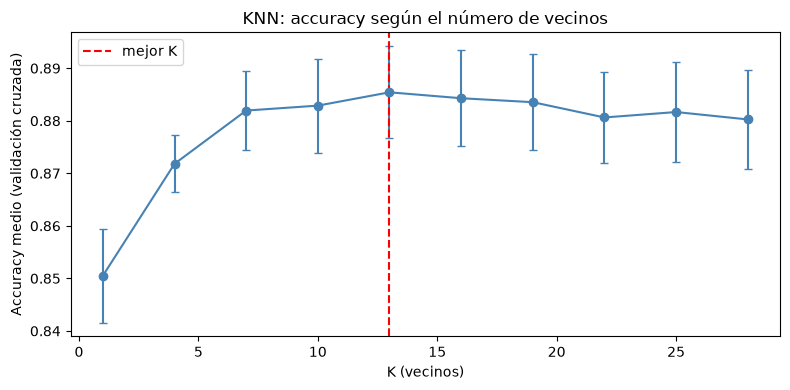

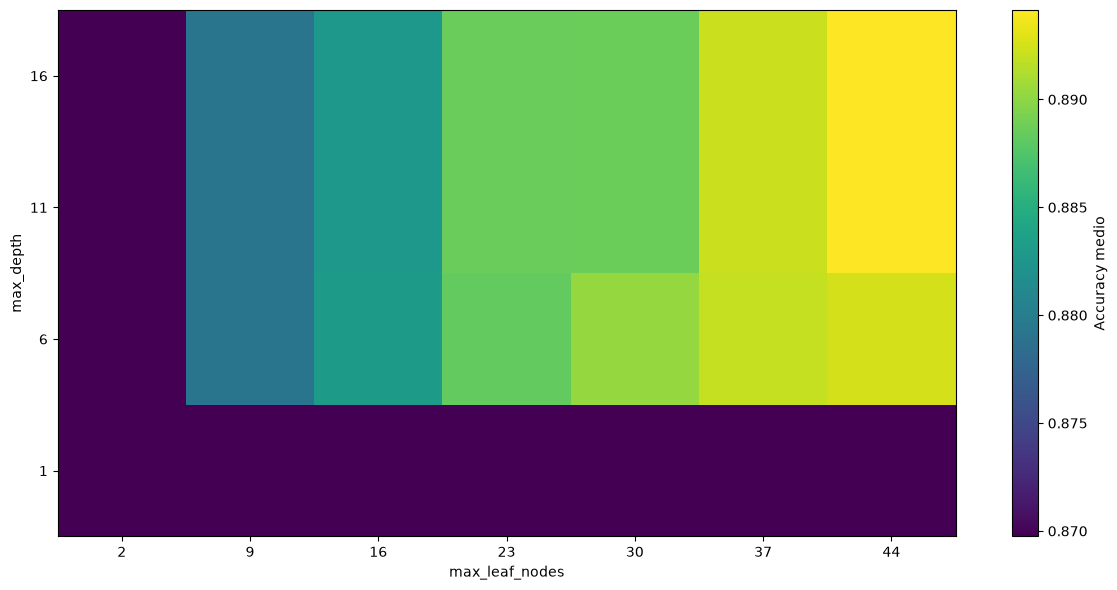

In [18]:
# KNN: accuracy medio frente a K
res_knn = pd.DataFrame(gs_knn.cv_results_)
x = res_knn["param_kneighborsclassifier__n_neighbors"].astype(int)
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(x, res_knn["mean_test_score"], yerr=res_knn["std_test_score"],
            marker="o", capsize=3, color="steelblue")
ax.axvline(gs_knn.best_params_["kneighborsclassifier__n_neighbors"], color="red", ls="--", label="mejor K")
ax.set_xlabel("K (vecinos)")
ax.set_ylabel("Accuracy medio (validación cruzada)")
ax.set_title("KNN: accuracy según el número de vecinos")
ax.legend()
plt.tight_layout()
plt.show()

# Árbol: mapa de calor de max_depth frente a max_leaf_nodes, con min_samples_split en su mejor valor
res_arbol = pd.DataFrame(gs_arbol.cv_results_)
mejor_mss = gs_arbol.best_params_["decisiontreeclassifier__min_samples_split"]
res_arbol = res_arbol[res_arbol["param_decisiontreeclassifier__min_samples_split"] == mejor_mss]

tabla = res_arbol.pivot_table(
    index="param_decisiontreeclassifier__max_depth",
    columns="param_decisiontreeclassifier__max_leaf_nodes",
    values="mean_test_score",
)

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(tabla.values, aspect="auto", origin="lower", cmap="viridis")
ax.set_xticks(range(0, tabla.shape[1], 5), tabla.columns[::5])
ax.set_yticks(range(tabla.shape[0]), tabla.index)
ax.set_xlabel("max_leaf_nodes")
ax.set_ylabel("max_depth")
ax.set_xticks(range(tabla.shape[1]), labels=tabla.columns)
fig.colorbar(im, ax=ax, label="Accuracy medio")
plt.tight_layout()
plt.show()


# TESTS #
Tras encontrar las mejores configuraciones para el arbol de decisión y KNN, pasaremos a probar el rendimiento de estos en el conjunto que hemos reservado para los tests:

In [19]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix

modelos_finales = {
    "Naive Bayes": make_pipeline(
        preprocessing, GaussianNB(priors=np.full(n_clases, 1 / n_clases))
    ).fit(X_train, y_train),
    "KNN afinado": gs_knn.best_estimator_,
    "Árbol afinado": gs_arbol.best_estimator_,
}

for nombre, modelo in modelos_finales.items():
    pred = modelo.predict(X_test)
    print(f"{nombre}: accuracy = {accuracy_score(y_test, pred):.4f}, "
          f"balanced accuracy = {balanced_accuracy_score(y_test, pred):.4f}")
    etiquetas = sorted(y_train.unique())
    print(pd.DataFrame(
        confusion_matrix(y_test, pred, labels=etiquetas),
        index=etiquetas,
        columns=etiquetas
    ), "\n")


Naive Bayes: accuracy = 0.0856, balanced accuracy = 0.3732
                 Entire home/apt  Private room  Shared room
Entire home/apt              114            44         1428
Private room                  41            77          923
Shared room                    1             0           37 

KNN afinado: accuracy = 0.8829, balanced accuracy = 0.6257
                 Entire home/apt  Private room  Shared room
Entire home/apt             1468           118            0
Private room                 160           881            0
Shared room                    6            28            4 

Árbol afinado: accuracy = 0.8923, balanced accuracy = 0.6720
                 Entire home/apt  Private room  Shared room
Entire home/apt             1504            82            0
Private room                 175           865            1
Shared room                    7            22            9 



## Conclusiones

Se compararon tres clasificadores (Naive Bayes, KNN y árbol de decisión) para predecir `room_type`. Los resultados sobre el conjunto de test (2665 anuncios) fueron:

| Modelo | Accuracy | Balanced accuracy |
|---|---|---|
| Referencia aleatoria estratificada | ~0.50 (validación cruzada) | — |
| Naive Bayes | 0.086 | 0.373 |
| KNN afinado (K = 13) | 0.883 | 0.626 |
| Árbol afinado (max_depth = 11, max_leaf_nodes = 44, min_samples_split = 2) | **0.892** | **0.672** |

- **El árbol de decisión es el mejor modelo**, con una ligera ventaja sobre KNN en las dos métricas. Ambos superan ampliamente la referencia aleatoria, lo que indica que las variables elegidas contienen información útil sobre el tipo de alojamiento.
- **La afinación mejoró algo los modelos**, sobre todo el árbol (de 0.855 a 0.894 en validación cruzada), y poco a KNN (de 0.878 a 0.885). El resultado sobre el test (0.892 para el árbol y 0.883 para KNN) es coherente con el de validación cruzada, sin señales de sobreajuste.
- **Naive Bayes no es adecuado para estos datos.** Predice casi todos los anuncios como "Shared room", con un accuracy peor que el azar. El supuesto de distribuciones gaussianas no se ajusta a variables asimétricas y a las columnas binarias de la codificación one-hot.
- **Las clases están muy desbalanceadas** (la clase "Shared room" es solo un 1,4 % de los datos). El accuracy alto de KNN y del árbol se debe a que acierta casi siempre con "Entire home/apt" y "Private room". Con "Shared room", KNN acierta 4 de 38 anuncios y el árbol, 9 de 38. Por eso el balanced accuracy (0.63 y 0.67) es bastante menor que el accuracy.
